In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

/Users/jameshunt/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
device

device(type='cpu')

In [4]:
ticker = 'AAPL'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [5]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568924,72.326889,71.345145,71.501549,146322800
2020-01-06,72.139183,72.177684,70.442784,70.693036,118387200
2020-01-07,71.799919,72.403881,71.580950,72.148820,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200
...,...,...,...,...,...
2026-09-21,338.980011,339.640015,333.049988,335.279999,34999200
2026-09-22,339.750000,345.339996,338.750000,340.140015,40711800


<Axes: xlabel='Date'>

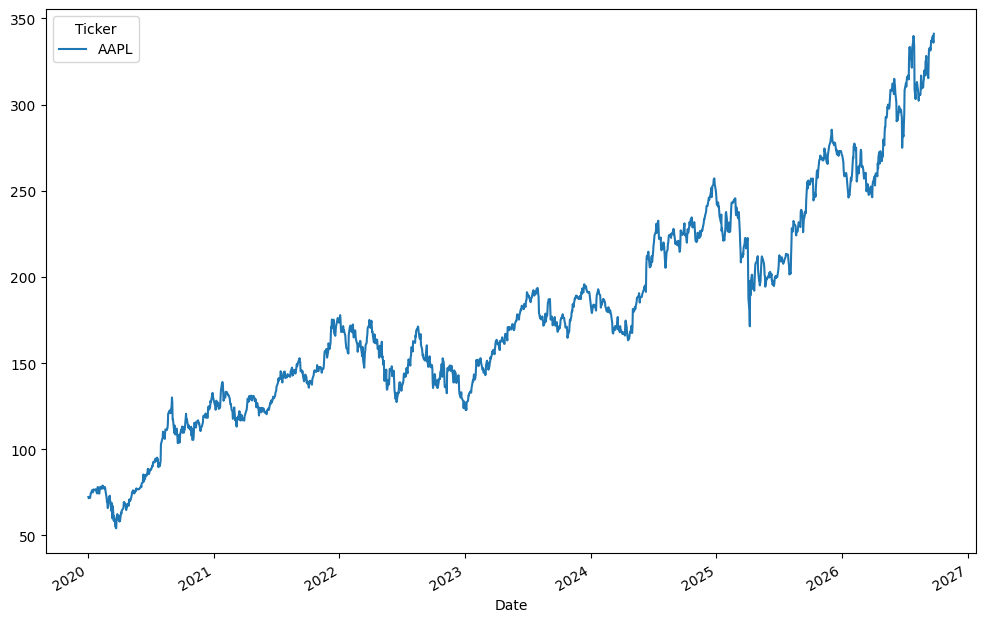

In [6]:
df.Close.plot(figsize=(12,8))

In [7]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df['Close'])

In [8]:
df['Close']

Ticker,AAPL
Date,
2020-01-02,-1.722065
2020-01-03,-1.733511
2020-01-06,-1.724222
2020-01-07,-1.729748
2020-01-08,-1.710934
...,...
2026-09-21,2.622411
2026-09-22,2.634953
2026-09-23,2.590483


In [9]:
seq_length =30
data=[]

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)
data

array([[[-1.72206536],
        [-1.73351065],
        [-1.72422157],
        ...,
        [-1.64360122],
        [-1.61378071],
        [-1.62293545]],

       [[-1.73351065],
        [-1.72422157],
        [-1.72974791],
        ...,
        [-1.61378071],
        [-1.62293545],
        [-1.62262078]],

       [[-1.72422157],
        [-1.72974791],
        [-1.71093412],
        ...,
        [-1.62293545],
        [-1.62262078],
        [-1.64599791]],

       ...,

       [[ 2.06743643],
        [ 2.02410701],
        [ 2.07313776],
        ...,
        [ 2.57598628],
        [ 2.62241069],
        [ 2.63495322]],

       [[ 2.02410701],
        [ 2.07313776],
        [ 2.08405126],
        ...,
        [ 2.62241069],
        [ 2.63495322],
        [ 2.59048344]],

       [[ 2.07313776],
        [ 2.08405126],
        [ 2.07851298],
        ...,
        [ 2.63495322],
        [ 2.59048344],
        [ 2.57256568]]])

In [10]:
train_size = int(0.8 * len(data))

X_train = torch.from_numpy(data[:train_size, : -1, :])
y_train = torch.from_numpy(data[:train_size, -1, :]) 
X_test = torch.from_numpy(data[train_size:, -1, :]) 
y_test = torch.from_numpy(data[train_size:, -1, :]) 

In [11]:
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()
        #self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        # self,output_dim = output_dim
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach())) 
        out = self.fc(out[:, -1, :]) 
        return out


In [12]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)